# [Dataset: Predicting Student Health Risk](https://www.kaggle.com/competitions/playground-series-s6e7)


# 1. Data Exploration

#### Step 1: Importing the main libararies we use & importing the raw datasets

In [ ]:
# import the libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import urllib.request
import zipfile
import os

# import sklearn main functions
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# import evaluating libraries
from sklearn.metrics import accuracy_score, precision_score, classification_report

In [ ]:
# unzip the file & start working on the data
url = "https://github.com/RonySoliman/Comprehensive-Course-Machine-Learning-In-Python/raw/main/Datasets/Predicting%20Student%20Health%20Risk/Predicting_Student_Health_Risk.zip"
zip_path = "Predicting_Student_Health_Risk.zip"
extract_path = "extracted_data"

# download the zip file
urllib.request.urlretrieve(url, zip_path)

# extract the data tables
os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

#### Step 2: Merge the different data tables

In [ ]:
# importing the data tables
train = pd.read_csv(os.path.join(extract_path, "train.csv"))
test = pd.read_csv(os.path.join(extract_path, "test.csv"))
sample_submission = pd.read_csv(os.path.join(extract_path, "sample_submission.csv"))

# get a copy of the original training set
df = train.copy()

In [ ]:
# dislay the first few rows
print(df.shape)
print("\n")
df.head(3)

(349623, 15)




,Id,Health_condition,Sleep_duration,Heart_rate,Bmi,Calorie_expenditure,Step_count,Exercise_duration,Water_intake,Diet_type,Stress_level,Sleep_quality,Physical_activity_level,Smoking_alcohol,Gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male


In [ ]:
# check the dtype of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690088 entries, 0 to 690087
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       690088 non-null  int64  
 1   health_condition         690088 non-null  object 
 2   sleep_duration           614089 non-null  float64
 3   heart_rate               682255 non-null  float64
 4   bmi                      676190 non-null  float64
 5   calorie_expenditure      637235 non-null  float64
 6   step_count               676172 non-null  float64
 7   exercise_duration        683187 non-null  float64
 8   water_intake             646611 non-null  float64
 9   diet_type                683187 non-null  object 
 10  stress_level             607277 non-null  object 
 11  sleep_quality            631757 non-null  object 
 12  physical_activity_level  653467 non-null  object 
 13  smoking_alcohol          661506 non-null  object 
 14  gend

In [ ]:
# check the % of NaN
df.isna().sum()/len(df)*100

,0
id,0.000000
health_condition,0.000000
sleep_duration,11.012943
heart_rate,1.135073
bmi,2.013946
calorie_expenditure,7.658878
step_count,2.016554
exercise_duration,1.000017
water_intake,6.300211
diet_type,1.000017


#### Simple Grpahs to understand the data skewness & correlation

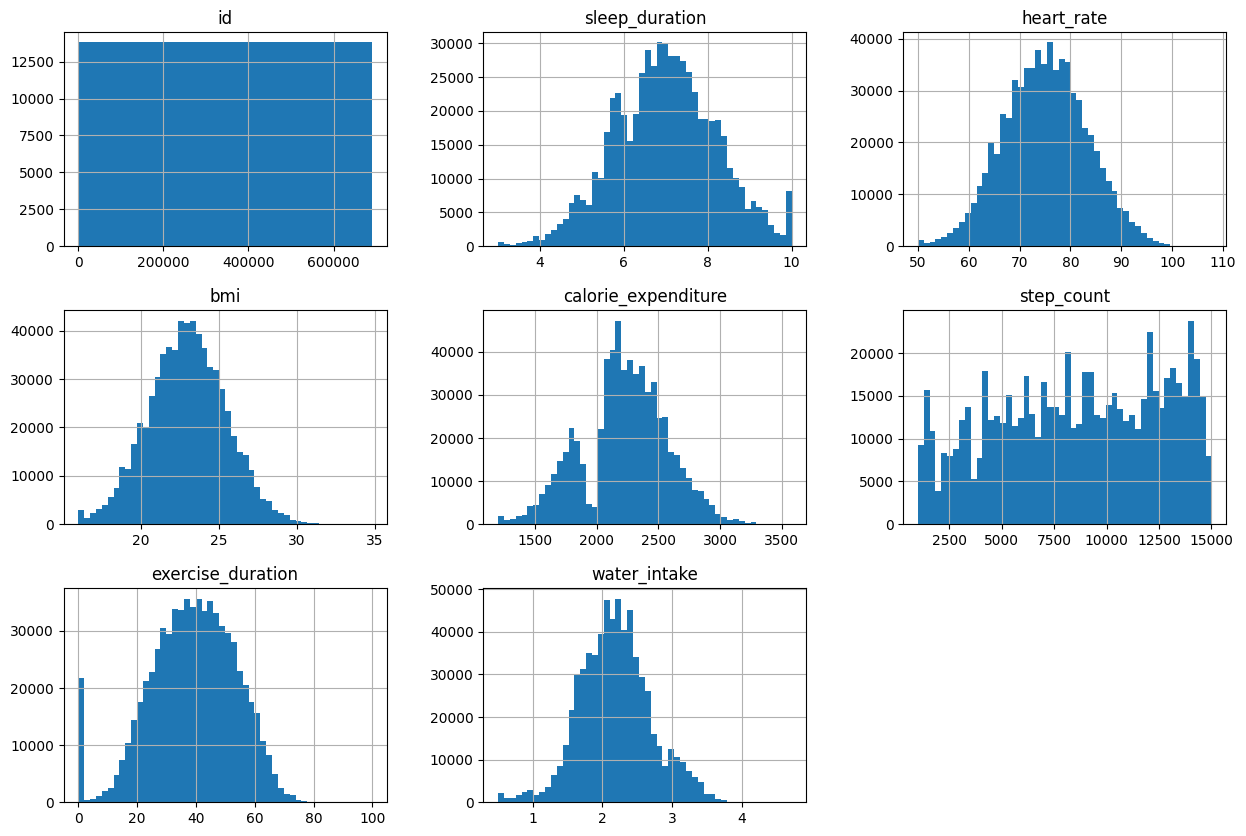

In [ ]:
df.hist(figsize=(15,10), bins=50);

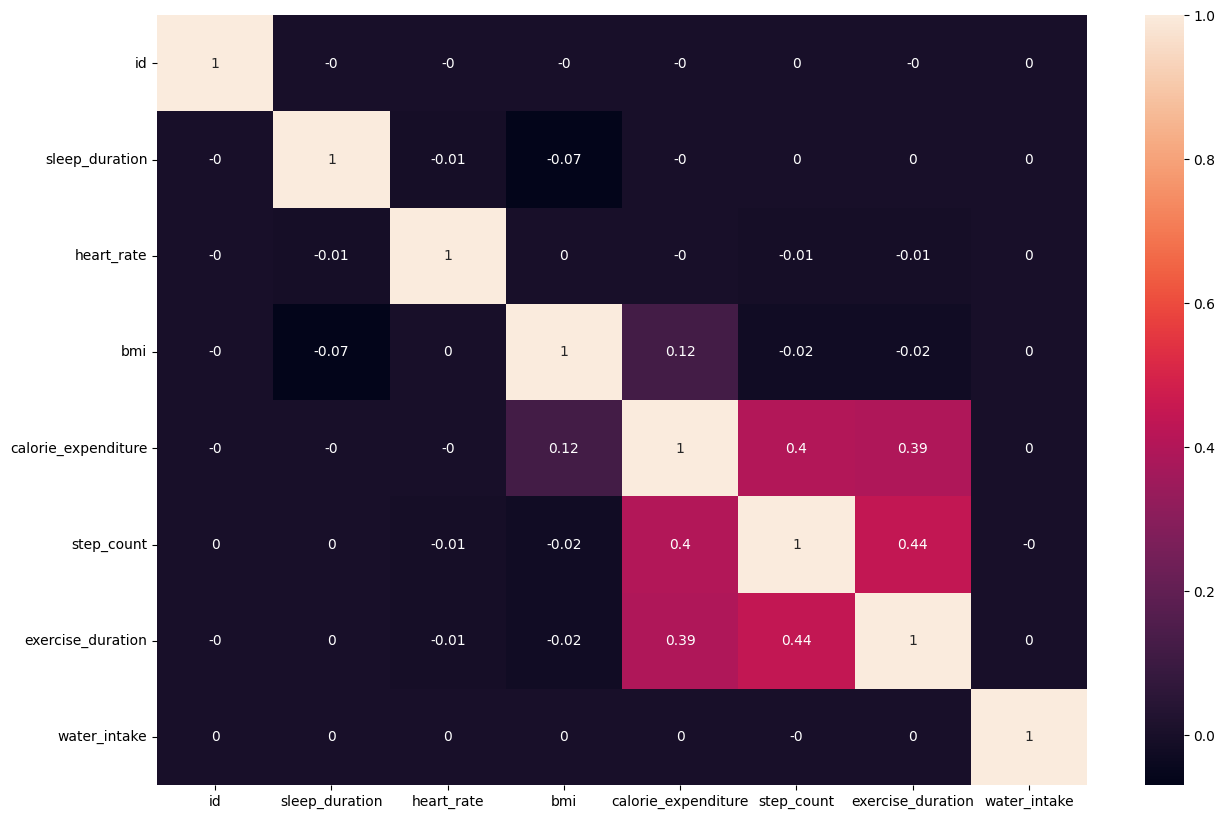

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(df.select_dtypes(include=[np.number]).corr().round(2), annot=True)
plt.show();

# 2. Data Cleaning

In [ ]:
df.health_condition.value_counts()/len(df.health_condition)*100 # the numeric values before deleting the NaN values

,count
health_condition,
at-risk,85.867455
unhealthy,8.364730
fit,5.767815


In [ ]:
# let's copy the dataset
dummy = df.copy()

In [ ]:
# drop the missing values
dummy = dummy.dropna()

In [ ]:
# count the number of the rows to see the before & after effect
dummy.health_condition.value_counts()/len(dummy.health_condition)*100

,count
health_condition,
at-risk,85.803280
unhealthy,8.469408
fit,5.727312


In [ ]:
df = df.dropna() # dropping the NaN

In [ ]:
# capitalize the first letter
df.columns = df.columns.str.capitalize()
test.columns = test.columns.str.capitalize()

In [ ]:
df.info() # To ensure the updates are executed successfully!

<class 'pandas.core.frame.DataFrame'>
Index: 349623 entries, 0 to 690087
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Id                       349623 non-null  int64  
 1   Health_condition         349623 non-null  object 
 2   Sleep_duration           349623 non-null  float64
 3   Heart_rate               349623 non-null  float64
 4   Bmi                      349623 non-null  float64
 5   Calorie_expenditure      349623 non-null  float64
 6   Step_count               349623 non-null  float64
 7   Exercise_duration        349623 non-null  float64
 8   Water_intake             349623 non-null  float64
 9   Diet_type                349623 non-null  object 
 10  Stress_level             349623 non-null  object 
 11  Sleep_quality            349623 non-null  object 
 12  Physical_activity_level  349623 non-null  object 
 13  Smoking_alcohol          349623 non-null  object 
 14  Gender   

# 3. Splitting Into Training & Testing Subsets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(["Id","Health_condition"], axis=1), df["Health_condition"], test_size=0.2, random_state=42)

# 4. Feature Engineering

1. Label Encoding > for the target response
2. One Hot Encoding > nominal categorical (Gender)
3. Ordinal Encoding > variables with an order (Stress Level - Sleep Level)

In [ ]:
# Label Encoding
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [ ]:
# One Hot Encoding
cat_cols = ["Gender", "Diet_type", "Physical_activity_level", "Smoking_alcohol"]
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)
# testing
test_encoded = pd.get_dummies(test, columns=cat_cols, drop_first=True)

In [ ]:
# ordinal Encoding
enc = OrdinalEncoder(categories="auto", handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1)

# execute
X_train_encoded[["Stress_level", "Sleep_quality"]] = enc.fit_transform(X_train_encoded[["Stress_level", "Sleep_quality"]])
X_test_encoded[["Stress_level", "Sleep_quality"]] = enc.transform(X_test_encoded[["Stress_level", "Sleep_quality"]])

test_encoded[["Stress_level", "Sleep_quality"]] = enc.transform(test_encoded[["Stress_level", "Sleep_quality"]])

# 5. Machine Learning Models

### Decision Tree Classifier

In [ ]:
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train_encoded, y_train);

In [ ]:
y_predict_dt = model_dt.predict(X_test_encoded)

### Model Evaluation Metrics (Decision Tree)

In [ ]:
print(accuracy_score(y_test, y_predict_dt))
print(classification_report(y_test, y_predict_dt));

0.9824240257418663
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     59944
           1       0.92      0.94      0.93      4067
           2       0.94      0.95      0.94      5914

    accuracy                           0.98     69925
   macro avg       0.95      0.96      0.95     69925
weighted avg       0.98      0.98      0.98     69925



### Random Forest Classifier

In [ ]:
model_rf = RandomForestClassifier(random_state=42) # n_estimators = 100
model_rf.fit(X_train_encoded, y_train);

In [ ]:
y_predict_rf = model_rf.predict(X_test_encoded);

### Model Evaluation Metrics (Random Forest)

In [ ]:
print(accuracy_score(y_test, y_predict_rf))
print(classification_report(y_test, y_predict_rf));

0.9919485162674294
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     59944
           1       0.99      0.95      0.97      4067
           2       0.99      0.95      0.97      5914

    accuracy                           0.99     69925
   macro avg       0.99      0.97      0.98     69925
weighted avg       0.99      0.99      0.99     69925



# 6. Applying On The Testing Subset

In [ ]:
test_ids = test_encoded["Id"]

enhanced_test = test_encoded.drop("Id", axis=1)

# predictions
predictions = model_rf.predict(enhanced_test);

In [ ]:
# output

output_df = pd.DataFrame(
{
    "id": test_ids,
    "health_condition": le.inverse_transform(predictions)
}
)

In [ ]:
output_df.to_csv("submission.csv", index=False)
output_df.head()

,id,health_condition
0,690088,unhealthy
1,690089,at-risk
2,690090,at-risk
3,690091,at-risk
4,690092,unhealthy


In [ ]:
Sample_submission = pd.read_csv("/content/extracted_data/sample_submission.csv")
Sample_submission.head(3)

,id,health_condition
0,690088,at-risk
1,690089,at-risk
2,690090,at-risk
